In [91]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Finite Element Methods: an introduction

The Finite Element Method (FEM) provides yet another method of transforming continuous PDE's to systems of discrete linear and non-linear equations and is particularly popular in Engineering and Solid Mechanics (although the method is completely general).  Finite Elements has a rich mathematical basis in functional analysis as well a very wide range of specialized applications.  Needless to say, this subject and the accompanying literature is vast.  The purpose of these notes are just to give you a very basic introduction to some of the fundamental ideas in Finite Elements and their implementation.

## Finite Dimensional Function spaces

A key idea in Finite Elements is that we will be approximating continuous functions $f(x)$ as a linear combination of a finite number of basis functions

$$
    f_h(x) = \sum_{i=0}^N w_i \phi_i(x)
$$

where $\phi_i(x)$ are the basis functions and $w_i$ are a set of weights.  We've seen similar decompositions for spectral methods. However instead of using global basis functions such as $\sin(kx)$ or Chebyshev polynomials,  we will (for the most part) use piecewise polynomials.


### Piecewise Linear Functions in 1-D (P1)

![](./images/P1_function_annotated_fig1.1LB.png)

As an example, consider the piecewise linear "connect the dots" function illustrated above where we have decomposed an interval $I=[x_0,x_5]$ into 5 sub-intervals or "elements"  $e_i = [x_{i},x_{i+1}]$ with $i=1\ldots 4$.  Over each of these intervals, the function $v_h$ is a linear function of $x$ and each segment is continuous at the element edge.  Figure modified from Figure 1.1 of Larson and Bengzon.  

While $v_h(x)$ is a continous function that can be evaluated for any value of $x$, it should be clear that there are really only 6 degrees of freedom corresponding to the values at the nodes $\vec v = [v_0,v_1,v_2,v_3,\ldots,v_5]$.  By just changing these 6 numbers, we can generate an infinite number of piecewise linear functions on this triangulation.  We will call this finite dimensional space of functions $\cal V_h$, which is fully described by a mesh of elements, and an interpolant over each element.  

### Global Basis Functions

Given any discrete function space $\cal V_h$, we should be able to describe any function $v_h\in \cal V_h$ in terms of a set of basis functions that span the space.  In the case of a 1-D piecewise linear function space, the global basis functions are given by the "Hat Functions"  

$$
\phi_i(x) = \left\{
\begin{array}{ll}
(x - x_{i-1})/\Delta x_{i-1}, & x\in e_{i-1} \\
(x_i - x)/\Delta x_{i}, & x\in e_{i} \\
0, & \text{otherwise} \\
\end{array}
\right.
$$

Which have the important property that $\phi_i(x_j) = \delta_{ij}$.  A typical hat function is shown in Figure 1.2 from Larson and Bengson.
![](./images/P1_Hat_function_fig1.2LB.png)

While it's not entirely obvious,  we can construct all piecewise linear functions in $\cal V_h$ as a linear combination of these hat functions, i.e. 

$$
f_h(x) = \sum_{i=0}^5 w_i\phi_i(x)
$$

### Local Basis Functions

To make this a bit clearer it is worth looking at how these basis functions interpolate $v$ over a single element.

![](./images/P1LocalBases.png)

> **Figure *3*: Definition of Global and Local Basis Functions**

Consider just the portion of $v(x)$ that lies in element $e_i$.  Clearly the only global basis functions that have support in element $e_i$ are $\phi_i(x)$ and $\phi_{i+1}(x)$.  We claim that over this element
$$
v(x) = v_i\phi_i(x) + v_{i+1}\phi_{i+1}(x)\quad\text{for}\quad x\in [x_i,x_{i+1}]
$$

This is clearly true at the nodes because of the property that $\phi_i(x_j) = \delta_{ij}$.  

Between the nodes, we expect that $\phi_i$ and $\phi_{i+1}$ provide linear interpolation.  If we just consider the *local basis functions* which are the parts of $\phi_i$ and $\phi_{i+1}$ in element $e_i$

\begin{align}
  N_0(x) & = (x_{i+1} - x)/(x_{i+1} - x_i)\\
  N_1(x) & = (x - x_i)/(x_{i+1} - x_i)\\
\end{align}

it becomes clear that these are just the Lagrange Polynomials of order 1 that interpolate any linear function over the interval $[x_i,x_{i+1}]$.   Just to check note that if $x* = x_i + t \Delta x_i$ where $s$ is the fractional distance across the element with length $\Delta x_i = x_{i+1} - x_i$, then
\begin{align}
  N_0(x*) & = (x_{i+1} - x_i -s \Delta x_i)/\Delta x_i = (1 - s)\\
  N_1(x*) & = (x_i + s \Delta x_i - x_i)/\Delta x_i = s\\
\end{align}

so that within $e_i$
$$ 
   v(x) = v_i N_0(x) + v_{i+1}N_1(x) = v_i(1 - s)  + v_{i+1} s
$$
with $s\in[0,1]$

Thus our full function $v(x)$ over the full domain $\Omega = [x_0,x_5]$ is just the union of these local linear pieces.  Throughout this introduction we will often move between the global view and the element view depending on which frame of reference is more convenience.

### Higher order polynomial Function Spaces

The space of piecewise linear functions is often referred to as $P_1$ but there are other choices.  For example, the space of piecewise quadratic functions ($P_2$) has a set of local basis functions that are simply the Lagrange Polynomials of order 2 and require three degrees of freedom per node.  The global basis functions are simply constructed out of the local ones.  The Figure shows a subset of basis functions for $P_2$ which are different for degrees of freedom at the centers and edges of elements (original figure from [Introduction to Finite Element Methods](http://hplgit.github.io/INF5620/doc/pub/sphinx-fem)

![](http://hplgit.github.io/INF5620/doc/pub/sphinx-fem/_images/mpl_fe_basis_p2_4e_lab.png)



## Interpolation of a function $f(x)$ onto $\cal V$

Given a set of basis functions $\phi_i(x)$ for a function space $\cal V$, it should be clear that not all functions can be represented exactly, without error in $\cal V$.  For example, given a smooth function $f(x)$ the question arises how to construct approximations $f_h(x) \in \cal V$ that minimize some measure of the error.  Actually there are multiple approaches.  The simplest approximation is simply the *interpolation* or *projection* of $f$ onto $\cal V$, which we will denote as $\pi f$, and define as the function $\pi f \in \cal V$ such that

$$
    \pi f (x) = \sum_{i=0}^N f(x_i)\phi(x)
$$

Given the interpolating properties of the Lagrange polynomials, it should be clear that

$$
\pi f(x_j) = f(x_j)
$$

i.e. the two functions have zero error at the degrees of freedom. 

Figure 1.3 from Larson and Bengzon shows the linear interpolant of a function $f$ onto a single element over the interval $[x_0,x_1]$.
![](./images/f_interpolation_P1_01.png)

Figure 1.4 from Larson and Bengzon shows the linear interpolant of a function $f$ onto a piecewise linear function space $\cal V$.

![](./images/f_interpolation_P1_02.png)

### Interpolation Errors

In general there will usually be an error between $f(x)$ and its interpolant $\pi f(x)$. Quantifying this error though usually requires defining some norm and as usual there are multiple choices.  As it turns out however,  a useful norm in finite elements is the $L^2$ norm of a function over a domain $\Omega$

$$
    ||f||_{L^2} = \left[ \int_\Omega f^2 dx\right]^{1/2}
$$

and its related norm

$$
    ||f||_{L^2(I)} = \left[ \int_I f^2 dx\right]^{1/2}
$$

over a sub-interval $I$ (usually an element).

Given these definitions, and the behavior of polynomial interpolation it is relatively straightforward to put the following estimates on the interpolation error

* Interpolation error over a single P1 linear element
$$ 
|| f - \pi f||_{L^2(I)} \leq C \Delta x^2||f''||_{L^2(I)}
$$
where $I_{i+1} = [x_i,x_{i+1}]$, $\Delta x = x_{i+1} - x_{i}$, C is a constant, and $||f''||_{L^2(I)}$ is a measure of the curvature of the function over the interval.  If $\Delta x=0$ or the function is linear over the interval, then the error is zero.

* Interpolation error over the whole domain
For a piecewise polynomial function, the errors in the interpolant onto $\cal V$ are simply the summation of the errors over the element i.e. 
$$ 
|| f - \pi f||^2_{L^2} \leq C \sum_{i=0}^N \Delta x_i^4||f''||^2_{L^2(I_i)}
$$

### Convergence

Given these error estimates, it is clear that the interpolant converges to the continuous function in the $L^2$ norm as $\Delta x\rightarrow 0$ which makes sense as we expect the interpolant to be a better approximation to $f$ for finer and finer meshes. For $P_1$ functions, the error converges as $\Delta x^2$,  higher order interpolants of *smooth* functions should converge more rapidly if the higher-order piecewise polynomial is a good approximation to the continuous function $f$.

In [111]:

def interpolant_1d(x, f_vals, xe):
    """
    Piecewise linear (hat function) interpolant of f on [0, 1].
    Given a set of nodal points and a set of it values x and f, and given xe a finer mesh
        lenx(x) = n+1 is the number of points in the notal set x = [x_0,...,x_n]
        n = number of elements in wich the set is divided I_i = [x_i, x_i+1] i=0,...,n-1
    
    Inputs:
        x : set of nodal points
        f_vals : set of values of f at the nodal points of x
        xe : Fine mech where we evaluate the interpolant
    Returns:
        x : nodal coordinates
        I : interpolated values on a fine grid (for plotting)
    """

    n = len(x) - 1  # number of elements in which we divide the x axis
    I = np.zeros_like(xe) #Creamos un array de zeros que tiene la misma dim y estructura que xe 

    # Loop over each element and assemble piecewise linear interpolant 
    # Recorremos los intervalos en lo que hemos dividido x y vamos construyendo el interpolante I
    for i in range(n):
        # Element nodes
        xL, xR = x[i], x[i+1] # Valores en los extremos del intervalo
        fL, fR = f_vals[i], f_vals[i+1] #Función en los valores del extremo del intervalo
                                        #Queremos almacenar el valor del interpolante en cada uno de los valores de xe
        # Points in this element
        mask = (xe >= xL) & (xe <= xR) #Valores de xe que se encuentran en el intervalo I_i estudiado
        xi = xe[mask] #xe restingido al intervalo en el que estamos

        # Linear interpolation (hat functions)
        phiL = (xR - xi) / (xR - xL)
        phiR = (xi - xL) / (xR - xL)

        I[mask] = fL * phiL + fR * phiR #Valor del interpolante en el intevalo restringido

    return xe, I

<>:17: SyntaxWarning: invalid escape sequence '\p'
<>:17: SyntaxWarning: invalid escape sequence '\p'
C:\Users\sergi\AppData\Local\Temp\ipykernel_25440\2081243153.py:17: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(xe, If, '-', label='Interpolant $\pi f(x)$')


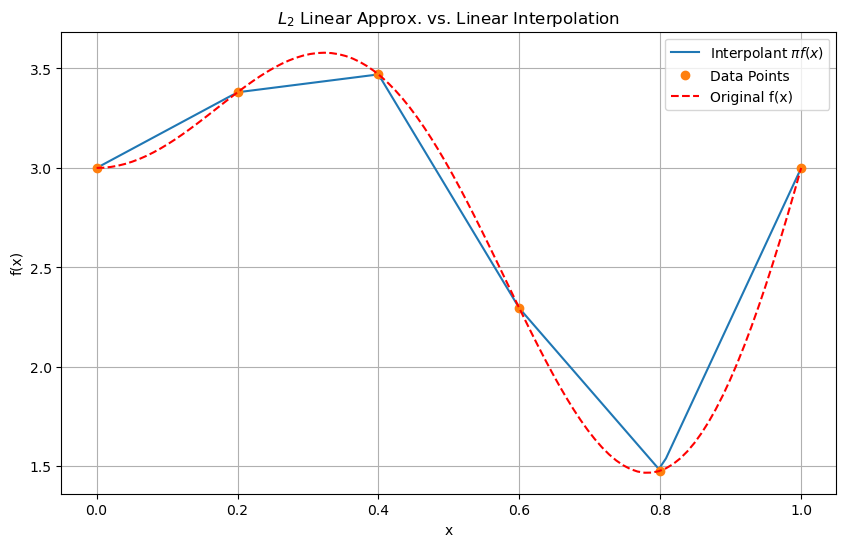

In [113]:
# Input data
n = 5  # number of subintervals
a, b = 0, 1
f = lambda x: 2*x*np.sin(2*np.pi*x) + 3

# nodal points and function values
x = np.linspace(a, b, n + 1)
f_vals = f(x) 


# linear interpolation
xe = np.linspace(a, b, 100)
xe, If = interpolant_1d(x,f_vals,xe)

# plot L^2 projection
plt.figure(figsize=(10, 6))
plt.plot(xe, If, '-', label='Interpolant $\pi f(x)$')
plt.plot(x, f(x), 'o', label='Data Points')

# Plot the original function for comparison
plt.plot(xe, f(xe), 'r--', label='Original f(x)')

plt.title('$L_2$ Linear Approx. vs. Linear Interpolation')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()



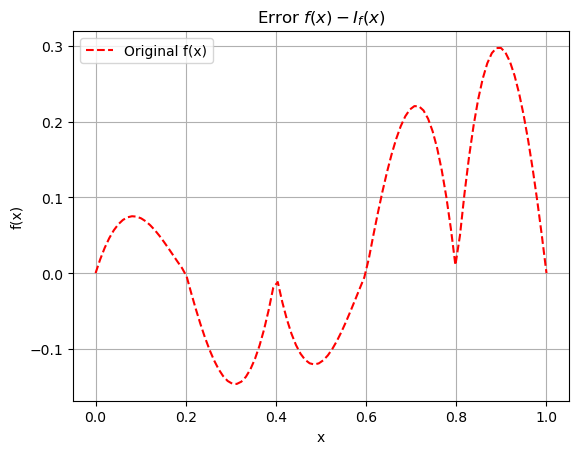

In [114]:
error_If = If - f(xe)

plt.plot(xe, error_If, 'r--', label='Original f(x)')
plt.title('Error $f(x)-I_f(x)$')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()


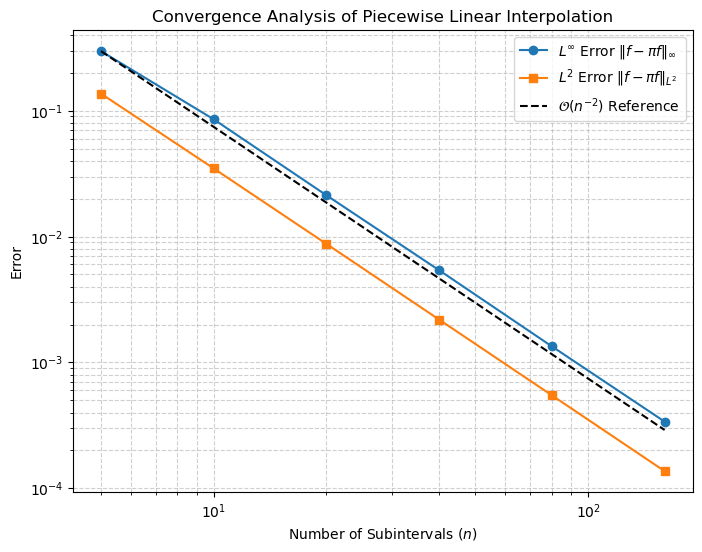

In [117]:
# Range of subintervals to test
a, b = 0, 1
f = lambda x: 2*x*np.sin(2*np.pi*x) + 3
n_values = [5, 10, 20, 40, 80, 160]
l_inf_errors = []
l2_errors = []

for n in n_values:
    # Nodal points and function values
    xe = np.linspace(a, b, 100)
    x = np.linspace(a, b, n + 1)
    f_vals = f(x)

    # Linear interpolation
    xe, If = interpolant_1d(x, f_vals, xe)
    error_If = f(xe) - If

    # Compute error norms
    l_inf_errors.append(np.max(np.abs(error_If)))
    l2_errors.append(np.sqrt(np.trapz(error_If**2, xe)))

# Plot convergence on a log-log scale
n_arr = np.array(n_values, dtype=float)

plt.figure(figsize=(8, 6))
plt.loglog(n_arr, l_inf_errors, 'o-', label='$L^\\infty$ Error $\\|f - \\pi f\\|_\\infty$')
plt.loglog(n_arr, l2_errors, 's-', label='$L^2$ Error $\\|f - \\pi f\\|_{L^2}$')

# Reference slope O(n^-2)
ref = l_inf_errors[0] * (n_arr[0] / n_arr)**2
plt.loglog(n_arr, ref, 'k--', label='$\\mathcal{O}(n^{-2})$ Reference')

plt.title('Convergence Analysis of Piecewise Linear Interpolation')
plt.xlabel('Number of Subintervals ($n$)')
plt.ylabel('Error')
plt.legend()
plt.grid(True, which='both', ls='--', alpha=0.6)
plt.show()

## $L_2$ Projection of a function $f(x)$ onto $\cal V$

While the interpolant $\pi f$ converges to $f$ in the $L^2$ norm as $\Delta x \rightarrow 0$, it turns out that for fixed $\Delta x$, it is not the function in $\cal V$ with the smallest $L^2$ error.  For that problem we need the orthogonal $L^2$ projection $P_h f$ which turns out to be the unique function $v_h\in\cal V$ that minimizes $||f - v_h||_{L^2}$.  
Figure 1.6 from Larson and Bengzon show the orthogonal projection of $f$ onto $\cal V$ for $f(x) = x\sin(\pi x)$

![](./images/f_projection_P1_01.png)


### Relationship to Least-Squares projection in linear algebra

Before we develop the machinery for calculating  the orthogonal $L^2$ projection of $f$ onto $\cal V$, $P_h f$,it is probably worth reviewing, briefly the related orthongal projection problem from linear algebra. 

![](./images/projection_figure.png)


Consider a 2-dimensional subspace $\cal S$ of $\mathbb R^3$ spanned by two linearly independent 3-D vectors $\boldsymbol{a}_1$ and $\boldsymbol{a}_2$. i.e.

$$
\cal S = \mathrm{span}<\boldsymbol{a}_1,\boldsymbol{a}_2>
$$ 

Let $\boldsymbol{b}$ be a third vector not in $\cal S$.  The problem is to find the point $\boldsymbol{p} \in \cal S$ that minimizes the Euclidian 2-norm of the error $\boldsymbol{e} = \boldsymbol{b} - \boldsymbol{p}$ where $||\boldsymbol{e}||_2 = \sqrt{\boldsymbol{e}^T\boldsymbol{e}}$

Inspection of the figure shows geometrically that the shortest error will be to find the point $\boldsymbol{p} = x_1\boldsymbol{a}_1 + x_2\boldsymbol{a}_2$ such that $\boldsymbol{e}$ is orthogonal to the plane $\cal S$.  If we define a matrix 

$$
A = \begin{bmatrix}
    \boldsymbol{a}_1 & \boldsymbol{a}_2
    \end{bmatrix}
$$

whose columns are the vectors $\boldsymbol{a}_1$ and $\boldsymbol{a}_2$, then $\boldsymbol{p} = A\boldsymbol{x}$ where 

$$
\boldsymbol{x} = \begin{bmatrix}
    x_1\\
    x_2
    \end{bmatrix}
$$

Now for $\boldsymbol{e}$ to be orthogonal to every vector in $\cal S$ it is sufficient for it to be orthogonal to the basis vectors $\boldsymbol{a}_1$ and $\boldsymbol{a}_2$.  Thus the requirement of orthogonality is that 

$$
    \boldsymbol{a}_i^T\boldsymbol{e} = 0
$$

for $i=1,2$.  This is equivalent to the statement $A^T\boldsymbol{e}=\boldsymbol{0}$  (or that the error is in the Left null space of $A$).

But
$$\begin{aligned}
    A^T\boldsymbol{e} & = A^T(\boldsymbol{b} - \boldsymbol{p}) \\
                      & = A^T(\boldsymbol{b} - A\boldsymbol{x}) \\
                      & = \boldsymbol{0}
\end{aligned}$$

or the Least-squares solution requires solving the Normal Equations

$$
    A^TA\boldsymbol{x} = A^T\boldsymbol{b}
$$

(although the numerically sensible  way to solve this is to actually use the QR factorization which is another application of orthogonal projection)

Given a solution $\boldsymbol{x}$, the projection is simply $\boldsymbol{p} = A\boldsymbol{x}$

### Orthogonal Projection of a function onto a discrete Function Space

If you understand the previous problem from linear algebra,  you'll realize that orthogonal projection of a function onto a discrete function space is essentially the same problem with slightly different machinery.  

The problem can be stated:

Given a continuous function $f(x)$ and discrete function space $\cal V_h$,  find the function $P_h f\in \cal V_h$ that minimizes $ || f - P_h f||_{L^2}$.  

Again, we can construct the problem geometrically.  First if $P_h f \in \cal V_h$ then we can write it in terms of the basis functions of $\cal V_h$ i.e.

$$
    P_h f(x)  = \sum_{j=0}^N w_j\phi_j(x)
$$

Next we construct the residual (or error) as

$$ 
    r(x) = f(x) - P_h f(x) 
$$
and require that the residual is "orthogonal" to every function $v_h\in \cal V_h$ where we define orthogonality of functions with respect to the $L^2$ norm in the usual way.  i.e. we say that $f$ and $g$ are orthogonal functions if

$$
    \int_\Omega fg dx = 0
$$

Therefore for $r$ to be orthogonal to every function $v_h\in \cal V_h$, it is only required that it be orthogonal to every basis function of $\cal V_h$.  For a finite dimensional function space the problem becomes find $P_h f \in \cal V_h$ such that

$$ 
    \int_\Omega \phi_i(x) r(x) dx = 0
$$ 
for all $i=0,\ldots,N$.  

Using our definitions for $r(x)$ and $P_h f(x)$, the problem becomes,  find the vector of weights $\boldsymbol{w} = [ w_0, w_1,\ldots, w_N]^T$ such that

$$
    \int_\Omega \phi_i(x)\sum_{j=0}^N w_j\phi_j(x) dx = \int_\Omega \phi_i(x) f(x) dx
$$ 
for all $i=0,\ldots,N$.  

Now the RHS of this equation is a set of $N$ numbers that each describes the $L^2$ inner product of $f$ with each basis function. Defining

$$
    \tilde{f}_i = \int_\Omega \phi_i(x) f(x) dx\quad i=0,\ldots,N
$$
the RHS assembles into a vector $\tilde{\boldsymbol{f}}\in \mathbb R^{N+1}$.  

The LHS is a bit more complicated but we can interchange summation and integration to rewrite the LHS as

$$
\int_\Omega \phi_i(x)\sum_{j=0}^N w_j\phi_j(x) dx = \sum_{j=0}^N w_j\int_\Omega \phi_i(x)\phi_j(x) dx
$$

Now the final definite integrals are another set of doubly indexed numbers

$$
    M_{ij} = \int_\Omega \phi_i(x)\phi_j(x) dx
$$

which define the entries of the "Mass Matrix" $M$.  

Thus the projection problem actually reduces to the linear algebra statement
$$
    \sum_{j=0}^N M_{ij}w_j = {b}_i
$$
or in matrix-vector notation, solve
$$
    M\boldsymbol{w} = \boldsymbol{b}
$$
for $\boldsymbol{w}$ then $P_h f(x)$ is defined by the weights and basis functions.

![](./images/FEM_projection_assembly.png)

Figure 9 showing all the components needed to assemble the mass matrix $M$ and the load vector $\tilde{\boldsymbol{f}}$

### Structure of the Mass Matrix

To understand the structure of the mass matrix, it is useful to examine the above figure.

Given a 1-D interval with $N$ elements,  the Mass Matrix $M$ is a $N+1\times N+1$ matrix who's components are given by 

$$
    M_{ij} = \int_\Omega \phi_i(x)\phi_j(x) dx
$$

If the basis functions were Orthonormal (e.g. sines and cosines or Chebyshev polynomials) the Mass Matrix would be equal to the Identity $I$.  However,  if the basis functions are hat functions examination of figure 9 shows that it should be sparse as Basis functions that don't share the same support should have $M_{ij}=0$.  For the case of an 1-D problems in $P_1$,  it should be clear that the Mass Matrix should actually be tri-diagonal  as the only non-zero elements will arise from the interaction of a basis function $\phi_i$ and it's two nearest neighbors $\phi_{i-1}$ and $\phi_{i+1}$

In particular,  the $i$th row of $M$ will have three non-zero entries

$$\begin{aligned}
    M_{i,i-1} &= \int_\Omega \phi_{i}\phi_{i-1} dx = \int_{x_{i-1}}^{x_i} \phi_{i}\phi_{i-1} dx \\
    M_{i,i} &= \int_\Omega \phi_{i}\phi_{i} dx = \int_{x_{i-1}}^{x_{i+1}} \phi_{i}\phi_{i} dx \\
    M_{i,i+1} &= \int_\Omega \phi_{i}\phi_{i+1} dx = \int_{x_i}^{x_{i+1}} \phi_{i}\phi_{i+1} dx \\
\end{aligned}$$

Note that the first term is contributed entirely by element $e_{i-1}$, the last term by element $e_i$ and the diagonal entry actually can be split into two parts

$$
    M_{i,i} = \int_{x_{i-1}}^{x_{i}} \phi_{i}\phi_{i} dx + \int_{x_{i}}^{x_{i+1}} \phi_{i}\phi_{i} dx
$$

corresponding to the contributions from both elements $e_{i-1}$ and $e_i$.  For simple  $P_1$ hat functions we can actually calculate these entries analytically (although for more complicated problems or the load matrix we might want to use numerical quadrature).  

If we just consider the first term and use the definitions of $\phi_{i-1}$ and $\phi_i$

$$
    M_{i,i-1} = \int_{x_{i-1}}^{x_i} \frac{x_{i} - x}{\Delta x_{i-1}} \frac{x - x_{i-1}}{\Delta x_{i-1}} dx 
$$

which is straightforward to integrate,  but is easier to do if we first make the affine transformation

$$
 x(t) = x_{i-1} + s \Delta x_{i-1}
$$

where again $s\in [0,1]$ is the fractional distance across element $e{i-1}$ ($s$ is also known as the local element coordinate).  Given this transformation and $dx = \Delta x_{i-1} ds$,  the above integral simplifies to

$$
        M_{i,i-1} = \Delta x_{i-1}\int_{0}^{1} ( 1- s) s ds = \Delta x_{i-1} \left.\left( \frac{s^2}{2} - \frac{s^3}{3}\right)\right|_0^1 = \frac{\Delta x_{i-1}}{6}
$$ 

Using the same approach we can evaluate the remaining terms
$$\begin{aligned}
M_{i,i} &= \Delta x_{i-1}\int_{0}^{1} s^2 ds  + \Delta x_i\int_{0}^{1} (1 - s)^2 ds = \frac{\Delta x_{i-1}}{3} + \frac{\Delta x_i}{3}\\
M_{i,i+1} & = \Delta x_i\int_{0}^{1} s(1-s) ds = \frac{\Delta x_i}{6}
\end{aligned}$$

so the stencil for one row of the mass matrix is simply

$$
M_i = \begin{bmatrix}
   \frac{\Delta x_{i-1}}{6}  & \frac{\Delta x_{i-1}}{3} + \frac{\Delta x_i}{3} & \frac{\Delta x_i}{6}
    \end{bmatrix}
$$

and the Global Mass matrix looks like
$$
    M = \begin{bmatrix}
    \frac{\Delta x_0}{3}  & \frac{\Delta x_0}{6} & & & & \\
    \frac{\Delta x_0}{6}  & \frac{\Delta x_0}{3} + \frac{\Delta x_1}{3} & \frac{\Delta x_1}{6} & & & \\
    &\frac{\Delta x_1}{6}  & \frac{\Delta x_1}{3} + \frac{\Delta x_2}{3} & \frac{\Delta x_2}{6}  & & \\
    & & \ddots & \ddots & \ddots & \\
    & & &   &  \frac{\Delta x_N}{6} & \frac{\Delta x_N}{3}
    \end{bmatrix}
$$

### Mechanics:  Element Wise Assembly 

While it is possible to assemble the global mass matrix as described above,  a better approach is to loop over each element and calculate the local contribution of each element to the global mass matrix.  To begin with we can decompose $M$ into a sum of simpler block matrices

$$
M = \begin{bmatrix}
\frac{\Delta x_0}{3}  & \frac{\Delta x_0}{6} & &  \\
\frac{\Delta x_0}{6}  & \frac{\Delta x_0}{3}  & & \\ 
&&& \\
&&& \\
&&& \\
&&& 
\end{bmatrix} +
\begin{bmatrix}
&&& \\
& \frac{\Delta x_1}{3}  & \frac{\Delta x_1}{6}   & \\ 
& \frac{\Delta x_1}{6}  & \frac{\Delta x_1}{3}  &  \\
&&& \\
&&& \\
&&& 
\end{bmatrix} + \ldots +
\begin{bmatrix}
&&& \\
&&& \\
&&& \\
&&& \\
& & \frac{\Delta x_N}{3}  & \frac{\Delta x_N}{6} \\
& &\frac{\Delta x_N}{6}  & \frac{\Delta x_N}{3}  
\end{bmatrix} 
$$

or

$$
M = M^{e_0} + M^{e_1} + \ldots + M^{e_N}
$$

where 

$$
  M^{e_i} = \frac{\Delta x_i}{6}\begin{bmatrix}
  2 & 1\\
  1 & 2
  \end{bmatrix}
  $$
  
  is the local element Mass Matrix for element $e_i$.  Examination of Figure 3 shows that we can describe the element mass matrix entirely in terms of the local basis functions $N_0(t)$ and $N_1(t)$ in the local coordinate system as
  
$$
  M^{e_i} = \Delta x_i\begin{bmatrix}
  \int_0^1 \phi_0^2 dt & \int_0^1 \phi_0\phi_1 dt \\
  \int_0^1 \phi_0\phi_1 dt & \int_0^1 \phi_1^2 dt 
\end{bmatrix}
$$

and each of these entries correspond to parts (or all) of entries in the global mass matrix

$$
  M^{e_i} = \begin{bmatrix}
  M_{i,i} & M_{i,i+1} \\
  M_{i+1,i} & M_{i+1,i+1} 
\end{bmatrix}
$$

So the overall algorithm is to 
* Loop over elements $i=0,\ldots,N$
* Calculate the local Mass Matrix $M^{e_i}$
* Insert/add into the Global Mass Matrix


In [127]:
def mass_assembler_1d(x):
    """
    Assembles the 1D mass matrix M of size (n+1)x(n+1) by computing a 2x2 blok by moving 
    in each of the intervals in which the grid is divided
    Inputs:
        x : Grid of points that are known x_0,...,x_n
    Returns:
        M : Matrix M
    
    """
    n = len(x) - 1  # number of subintervals in wich x is divided I_i, i=0,...,n-1
    M = np.zeros((n + 1, n + 1))  # allocate mass matrix

    #Recorremos los intervalos desde I_0 hasta el I_n-1 y calculamos el valor del bloque de 2x2
    for i in range(n):
        h = x[i+1] - x[i]  # interval length
        M[i, i] = M[i, i] + h / 3
        M[i, i+1] = M[i, i+1] + h / 6
        M[i+1, i] = M[i+1, i] + h / 6
        M[i+1, i+1] = M[i+1, i+1] + h / 3

    return M

### Assembly of Load Vector

We next calculate the load vector $b$. Because the entries $b_i = \int_I f \varphi_i \, dx$ depend on the function $f$, we can not generally expect to calculate them exactly. However, we can approximate entry $b_i$ using a quadrature rule. Using the Trapezoidal rule, for instance, we have
\begin{align*}
b_i &= \int_I f \varphi_i \, dx \\
    &= \int_{x_{i-1}}^{x_{i+1}} f \varphi_i \, dx \\
    &= \int_{x_{i-1}}^{x_i} f \varphi_i \, dx + \int_{x_i}^{x_{i+1}} f \varphi_i \, dx \\
    &\approx (f(x_{i-1})\varphi_i(x_{i-1}) + f(x_i)\varphi_i(x_i))h_i/2 \\
    &\quad + (f(x_i)\varphi_i(x_i) + f(x_{i+1})\varphi_i(x_{i+1}))h_{i+1}/2 \\
    &= (0 + f(x_i))h_i/2 + (f(x_i) + 0)h_{i+1}/2 \\
    &= f(x_i)(h_i + h_{i+1})/2
\end{align*}

The approximate load vector then takes the form
$$
b = \begin{bmatrix}
f(x_0)h_1/2 \\
f(x_1)(h_1 + h_2)/2 \\
f(x_2)(h_2 + h_3)/2 \\
\vdots \\
f(x_{n-1})(h_{n-1} + h_n)/2 \\
f(x_n)h_n/2
\end{bmatrix}
$$

Splitting $b$ into a sum over the elements yields the $n$ global element load vectors $b^{I_i}$
$$
\begin{aligned}
b &= \begin{bmatrix}
f(x_0) \\
f(x_1) \\
\vphantom{f(x_2)} \\
\vphantom{f(x_n)}
\end{bmatrix} h_1/2
+ \begin{bmatrix}
\vphantom{f(x_0)} \\
f(x_1) \\
f(x_2) \\
\vphantom{f(x_n)}
\end{bmatrix} h_2/2
+ \ldots + \begin{bmatrix}
\vphantom{f(x_0)} \\
\vphantom{f(x_1)} \\
f(x_{n-1}) \\
f(x_n)
\end{bmatrix} h_n/2 \\
&= b^{I_1} + b^{I_2} + \ldots + b^{I_n}.
\end{aligned}
$$


**Assembly Algorithm:**
1.  Initialize a global $b = 0$.
2.  Loop $i = 1$ to $n$ (over all elements):
    * Compute $b^I$ (using quadrature).
    * Add its entries to the global vector:
        - $b_{i-1} \mathrel{+}= b^{I_1}$
        - $b_i \mathrel{+}= b^{I_2}$



In [130]:
def load_assembler_1d_exact(x, f):
    """
    Assembles the 1D load vector exactly using numerical integration (quad).
    """
    n = len(x) - 1
    b = np.zeros(n + 1)

    for i in range(n):
        xL, xR = x[i], x[i + 1]
        h = xR - xL

        # Define local hat functions
        phiL = lambda s: (xR - s) / h
        phiR = lambda s: (s - xL) / h

        # Integrate exactly (to machine precision)
        b[i]     += quad(lambda s: f(s) * phiL(s), xL, xR)[0]
        b[i + 1] += quad(lambda s: f(s) * phiR(s), xL, xR)[0]

    return b


def load_assembler_1d(x, f_vals):
    """
    Assembles the 1D load vector using the trapezoidal rule.
    """
    n = len(x) - 1  # number of subintervals
    b = np.zeros(n + 1)
    for i in range(n):
        h = x[i+1] - x[i]  # interval length
        b[i] = b[i] + f_vals[i] * h / 2
        b[i+1] = b[i+1] + f_vals[i+1] * h / 2

    return b

Now we can perform a convergence test in order to be able to compare both ways to compute the right hand side of the system between the who ensamble methods that we have computed:
- b_exact: Exact integration of f
- b: Integration of f with a quadratre rule (trapezoidal)



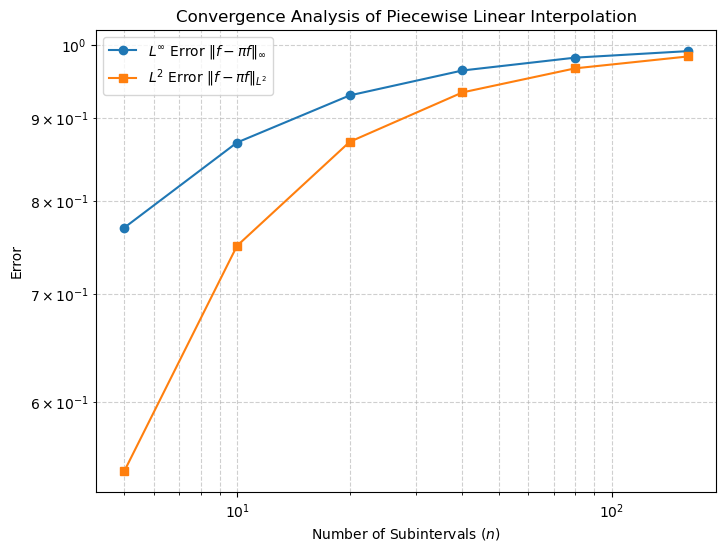

In [137]:
# Range of subintervals to test
a, b = 0, 1
f = lambda x: 2*x*np.sin(2*np.pi*x) + 3
n_values = [5, 10, 20, 40, 80, 160]

l_inf_errors = []
l2_errors = []

for n in n_values:
    # Nodal points and function values
    x = np.linspace(a, b, n + 1)
    f_vals = f(x)

    # Linear interpolation
    

    b_exact = load_assembler_1d_exact(x, f)
    b_num = load_assembler_1d(x, f_vals)

    error = b_exact - b

    # Compute error norms
    l_inf_errors.append(np.max(np.abs(error)))
    l2_errors.append(np.sqrt(np.trapz(error**2, x)))

# Plot convergence on a log-log scale
n_arr = np.array(n_values, dtype=float)

plt.figure(figsize=(8, 6))
plt.loglog(n_arr, l_inf_errors, 'o-', label='$L^\\infty$ Error $\\|f - \\pi f\\|_\\infty$')
plt.loglog(n_arr, l2_errors, 's-', label='$L^2$ Error $\\|f - \\pi f\\|_{L^2}$')

plt.title('Convergence Analysis of Piecewise Linear Interpolation')
plt.xlabel('Number of Subintervals ($n$)')
plt.ylabel('Error')
plt.legend()
plt.grid(True, which='both', ls='--', alpha=0.6)
plt.show()

In [147]:
def l2_projector_1d(x,f_vals):
    """
    Main L2 projection routine
    """
    M = mass_assembler_1d(x)
    b = load_assembler_1d(x,f_vals)

    # solve linear system (M * Pf = b)
    Pf = np.linalg.solve(M, b)

    return Pf


In [149]:
def l2_projector_1d_exact(x,f):
    """
    Main L2 projection routine
    """
    M = mass_assembler_1d(x)
    b = load_assembler_1d_exact(x,f)

    # solve linear system (M * Pf = b)
    Pf_exact = np.linalg.solve(M, b)

    return Pf_exact

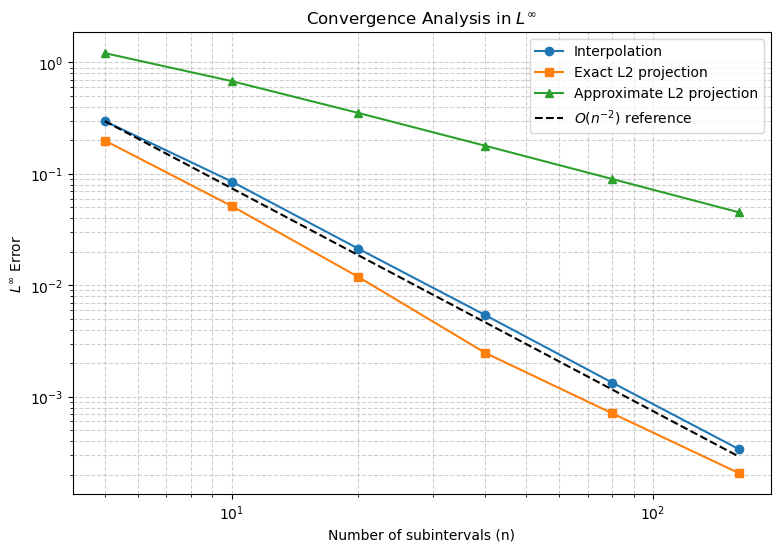

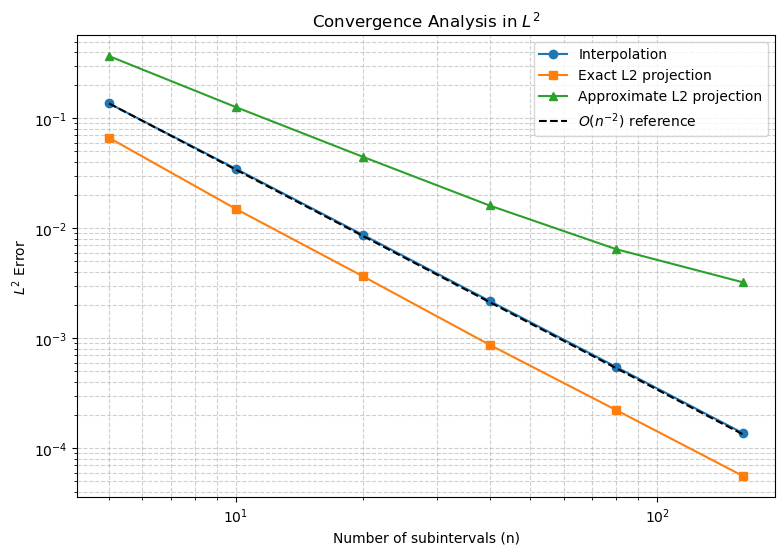

In [167]:
# Range of subintervals to test
a, b = 0, 1
f = lambda x: 2*x*np.sin(2*np.pi*x) + 3
n_values = [5, 10, 20, 40, 80, 160]
xe = np.linspace(a, b, 100)

inf_interp, l2_interp = [], []
inf_proj_exact, l2_proj_exact = [], []
inf_proj_approx, l2_proj_approx = [], []

for n in n_values:
    # Nodal points and function values
    x = np.linspace(a, b, n + 1)
    f_vals = f(x)

    # 1. Piecewise linear interpolation
    xe, If = interpolant_1d(x, f_vals, xe)
    error_I = f(xe) - If

    # 2. Exact L2 projection
    Pf_exact = l2_projector_1d_exact(x, f)
    xe, PIf_exact = interpolant_1d(x, Pf_exact, xe)
    error_P_exact = f(xe) - PIf_exact

    # 3. Approximate L2 projection
    Pf_approx = l2_projector_1d(x, f_vals)
    xe, PIf_approx = interpolant_1d(x, Pf_approx, xe)
    error_P_approx = f(xe) - PIf_approx

    # Compute L-infinity errors
    inf_interp.append(np.max(np.abs(error_I)))
    inf_proj_exact.append(np.max(np.abs(error_P_exact)))
    inf_proj_approx.append(np.max(np.abs(error_P_approx)))

    # Compute L2 errors
    l2_interp.append(np.sqrt(np.trapz(error_I**2, xe)))
    l2_proj_exact.append(np.sqrt(np.trapz(error_P_exact**2, xe)))
    l2_proj_approx.append(np.sqrt(np.trapz(error_P_approx**2, xe)))

# Plot convergence on a log-log scale
# Plot convergence in L-infinity
n_arr = np.array(n_values, dtype=float)

plt.figure(figsize=(9, 6))

plt.loglog(n_arr, inf_interp, 'o-', label='Interpolation')
plt.loglog(n_arr, inf_proj_exact, 's-', label='Exact L2 projection')
plt.loglog(n_arr, inf_proj_approx, '^-', label='Approximate L2 projection')

ref = inf_interp[0] * (n_arr[0] / n_arr)**2
plt.loglog(n_arr, ref, 'k--', label='$O(n^{-2})$ reference')

plt.xlabel('Number of subintervals (n)')
plt.ylabel('$L^\\infty$ Error')
plt.title('Convergence Analysis in $L^\\infty$')
plt.legend()
plt.grid(True, which='both', ls='--', alpha=0.6)
plt.show()


# Plot convergence in L2
plt.figure(figsize=(9, 6))

plt.loglog(n_arr, l2_interp, 'o-', label='Interpolation')
plt.loglog(n_arr, l2_proj_exact, 's-', label='Exact L2 projection')
plt.loglog(n_arr, l2_proj_approx, '^-', label='Approximate L2 projection')

ref = l2_interp[0] * (n_arr[0] / n_arr)**2
plt.loglog(n_arr, ref, 'k--', label='$O(n^{-2})$ reference')

plt.xlabel('Number of subintervals (n)')
plt.ylabel('$L^2$ Error')
plt.title('Convergence Analysis in $L^2$')
plt.legend()
plt.grid(True, which='both', ls='--', alpha=0.6)
plt.show()

### Convergence/Optimality

* The $L^2$-projection $P_h f$ satisfies the best approximation result

$$
\| f - P_h f \|_{L^2(I)} \leq \| f - v \|_{L^2(I)}, \quad \forall v \in V_h
$$

* The $L^2$-projection $P_h f$ satisfies the estimate

$$
\| f - P_h f \|_{L^2(I)}^2 \leq C \sum_{i=1}^n h_i^4 \| f'' \|_{L^2(I_i)}^2 
$$

<>:25: SyntaxWarning: invalid escape sequence '\p'
<>:26: SyntaxWarning: invalid escape sequence '\p'
<>:27: SyntaxWarning: invalid escape sequence '\p'
<>:25: SyntaxWarning: invalid escape sequence '\p'
<>:26: SyntaxWarning: invalid escape sequence '\p'
<>:27: SyntaxWarning: invalid escape sequence '\p'
C:\Users\sergi\AppData\Local\Temp\ipykernel_25440\4008653266.py:25: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(xe, If, '-', label='Interpolant $\pi f(x)$')
C:\Users\sergi\AppData\Local\Temp\ipykernel_25440\4008653266.py:26: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(xe, PIf_exact, 'o-', label='Interpolant $\pi f(x)$')
C:\Users\sergi\AppData\Local\Temp\ipykernel_25440\4008653266.py:27: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(xe, PIf_approx, 's-', label='Interpolant $\pi f(x)$')


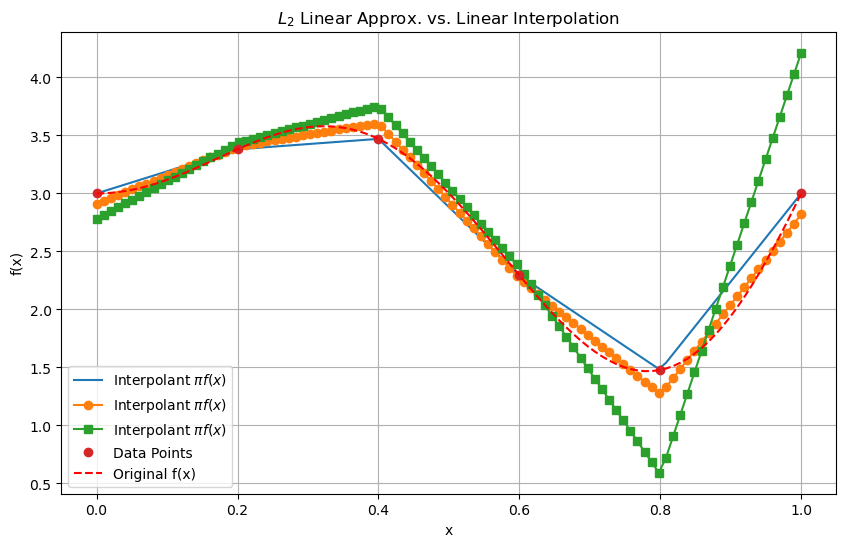

In [171]:
# Input data
n = 5  # number of subintervals
a, b = 0, 1
f = lambda x: 2*x*np.sin(2*np.pi*x) + 3

# nodal points and function values
x = np.linspace(a, b, n + 1)
f_vals = f(x) 
xe = np.linspace(a, b, 100)

# linear interpolation
xe, If = interpolant_1d(x,f_vals,xe)

# 2. Exact L2 projection
Pf_exact = l2_projector_1d_exact(x, f)
xe, PIf_exact = interpolant_1d(x, Pf_exact, xe)

# 3. Approximate L2 projection
Pf_approx = l2_projector_1d(x, f_vals)
xe, PIf_approx = interpolant_1d(x, Pf_approx, xe)

# plot L^2 projection
plt.figure(figsize=(10, 6))

plt.plot(xe, If, '-', label='Interpolant $\pi f(x)$')
plt.plot(xe, PIf_exact, 'o-', label='Interpolant $\pi f(x)$')
plt.plot(xe, PIf_approx, 's-', label='Interpolant $\pi f(x)$')

plt.plot(x, f(x), 'o', label='Data Points')

# Plot the original function for comparison
plt.plot(xe, f(xe), 'r--', label='Original f(x)')

plt.title('$L_2$ Linear Approx. vs. Linear Interpolation')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()